### Análisis exploratorio: BENIGN y ataques lentos

Describe el dataset que deja `limpieza_low_and_slow.ipynb` (`data/processed/wednesday_low_and_slow_clean.csv`): tráfico benigno y ataques Slowloris y Slowhttptest del miércoles 5/7/2017 de CIC-IDS2017. **Se ejecuta después del cuaderno de limpieza.**

El análisis usa el dataset ya limpio: `Timestamp` en reloj de 24 horas, sin identificadores, sin atajos del laboratorio (`Destination Port`, `Protocol`), sin columnas redundantes ni constantes y sin los 6 ataques fuera de ventana. El cuaderno comprueba primero que el archivo cumpla esas condiciones.

Es un análisis **descriptivo**, previo al modelado. Calcula estadísticas con el dataset completo para entender los datos, pero **no toma decisiones de modelado**: la selección de características y cualquier ajuste que dependa de la etiqueta se hacen después, solo con la partición de entrenamiento, para evitar fuga de información.

Las cifras que se citen en el informe deben tomarse de las salidas de este cuaderno, no transcribirse a mano.

In [ ]:
import sys
sys.path.append("../..")  # raíz del repo

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split

from src.preprocessing.clean import (
    cargar_dataset_limpio,
    VENTANAS_ATAQUE_DOCUMENTADAS,
    COLUMNAS_A_ELIMINAR_CANDIDATAS,
    COLUMNAS_ATAJO_LABORATORIO,
    COLUMNAS_REDUNDANTES,
    COLUMNAS_CONSTANTES,
    HORA_INICIO_CAPTURA,
    HORA_FIN_CAPTURA,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
sns.set_style("whitegrid")

RANDOM_STATE = 42
FIG_DIR = Path("../../reports/figures/eda")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Un color fijo por clase para que las figuras sean comparables
COLORES = {"BENIGN": "steelblue", "DoS slowloris": "crimson", "DoS Slowhttptest": "darkorange"}

**1. Carga y verificación del dataset**

`cargar_dataset_limpio()` lee el CSV y convierte `Timestamp` a fecha (el CSV lo guarda como texto). Luego se comprueba que el archivo corresponde a la versión actual de la limpieza. Si falla alguna comprobación, probablemente el CSV se generó antes de los últimos cambios de `clean.py` y hay que volver a correr el cuaderno de limpieza.

In [15]:
file_path = "../../data/processed/wednesday_low_and_slow_clean.csv"
df = cargar_dataset_limpio(file_path)

COLUMNAS_META = ["Timestamp", "Label", "label_binaria"]
features = [c for c in df.columns if c not in COLUMNAS_META]
y = df["label_binaria"]

print(f"Dataset cargado: {df.shape[0]:,} filas x {df.shape[1]} columnas "
      f"({len(features)} features + {len(COLUMNAS_META)} columnas de metadata/etiqueta)")

# El CSV debe corresponder a la versión vigente de la limpieza
assert pd.api.types.is_datetime64_any_dtype(df["Timestamp"]), "Timestamp no es datetime"
horas = df["Timestamp"].dt.hour
assert horas.between(HORA_INICIO_CAPTURA, HORA_FIN_CAPTURA).all(), "Horas fuera del horario de captura"
assert horas.max() >= 13, "No hay tráfico de la tarde: el CSV no tiene la corrección AM/PM"

eliminadas = (COLUMNAS_A_ELIMINAR_CANDIDATAS + COLUMNAS_ATAJO_LABORATORIO
              + COLUMNAS_REDUNDANTES + COLUMNAS_CONSTANTES)
presentes = [c for c in eliminadas if c in df.columns]
assert not presentes, f"Columnas que la limpieza debió eliminar siguen presentes: {presentes}"

no_numericas = [c for c in features if not pd.api.types.is_numeric_dtype(df[c])]
assert not no_numericas, f"Features no numéricas: {no_numericas}"
assert not df[features].isna().any().any(), "Hay valores nulos en las features"
assert not np.isinf(df[features].to_numpy(dtype=float)).any(), "Hay valores infinitos en las features"

print(f"Rango de Timestamp: {df['Timestamp'].min()} -> {df['Timestamp'].max()}")
print("OK: Timestamp corregido, columnas eliminadas ausentes, sin nulos ni infinitos.")

Dataset cargado: 443,614 filas x 62 columnas (59 features + 3 columnas de metadata/etiqueta)
Rango de Timestamp: 2017-07-05 08:42:00 -> 2017-07-05 17:10:00
OK: Timestamp corregido, columnas eliminadas ausentes, sin nulos ni infinitos.


**2. Tipos de dato, constantes y valores negativos**

Se revisa que ninguna característica haya quedado constante y cuáles conservan valores negativos. La limpieza elimina negativos solo en duración, `Flow IAT Min` y tasas; en otras columnas un negativo puede ser legítimo. Por ejemplo, `Init_Win_bytes_*` = -1 es el valor que usa CICFlowMeter para "no disponible". Esto importa al elegir la transformación logarítmica: `log1p` no admite valores ≤ -1.

In [16]:
print("Tipos de dato de las features:")
print(df[features].dtypes.value_counts().to_string())

constantes = [c for c in features if df[c].nunique() <= 1]
print(f"\nFeatures constantes: {constantes if constantes else 'ninguna'}")

negativos = (df[features] < 0)
cols_con_negativos = negativos.columns[negativos.any()].tolist()
print(f"\nColumnas con valores negativos: {len(cols_con_negativos)}")
if cols_con_negativos:
    resumen_neg = pd.DataFrame({
        "filas_negativas": negativos[cols_con_negativos].sum(),
        "en_ataques": negativos.loc[y == 1, cols_con_negativos].sum(),
        "valor_min": df[cols_con_negativos].min(),
    })
    print(resumen_neg.to_string())

Tipos de dato de las features:
float64    35
int64      24

Features constantes: ninguna

Columnas con valores negativos: 4
                         filas_negativas  en_ataques  valor_min
Fwd Header Length                      1           0        -11
Init_Win_bytes_forward            203252           0         -1
Init_Win_bytes_backward           264837        4812         -1
min_seg_size_forward                   1           0         -1


**3. Distribución de clases**

La clasificación del proyecto es binaria, pero también se muestra el desglose por tipo de ataque, porque los resultados se reportan por separado para Slowloris y Slowhttptest.

Label
BENIGN              432325
DoS slowloris         5790
DoS Slowhttptest      5499

Proporción de ataques: 2.5448%
Relación BENIGN : ataque ≈ 38.3 : 1


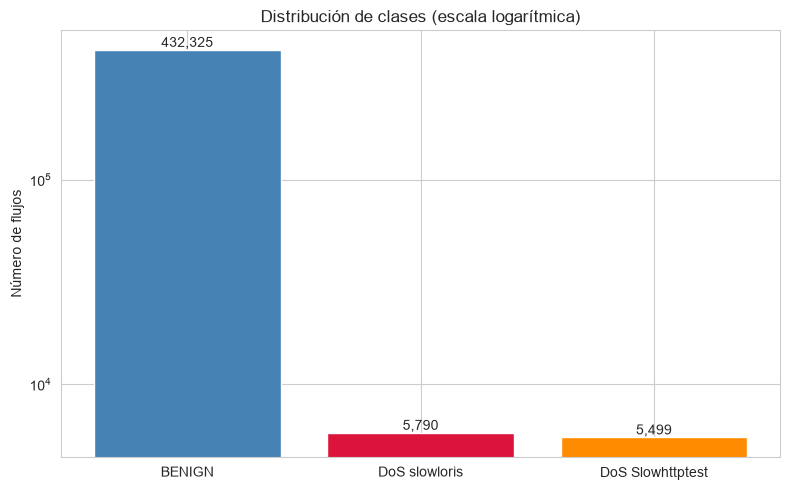

In [17]:
conteo = df["Label"].value_counts()
print(conteo.to_string())
print(f"\nProporción de ataques: {y.mean():.4%}")
print(f"Relación BENIGN : ataque ≈ {(y == 0).sum() / (y == 1).sum():.1f} : 1")

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(conteo.index, conteo.values, color=[COLORES[c] for c in conteo.index])
ax.set_yscale("log")  # con 38:1 los ataques serían casi invisibles en escala lineal
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_title("Distribución de clases (escala logarítmica)")
ax.set_ylabel("Número de flujos")
plt.tight_layout()
plt.savefig(FIG_DIR / "distribucion_clases.png", dpi=150)
plt.show()

**4. Distribución temporal de los flujos**

Muestra cuántos flujos hay por minuto durante la captura y dónde caen los ataques respecto de sus ventanas documentadas (franjas sombreadas). Sirve para confirmar que la corrección del reloj de 12 horas produjo una jornada continua de 08:42 a 17:10 y para entender la partición cronológica por bloques que usa el modelo.

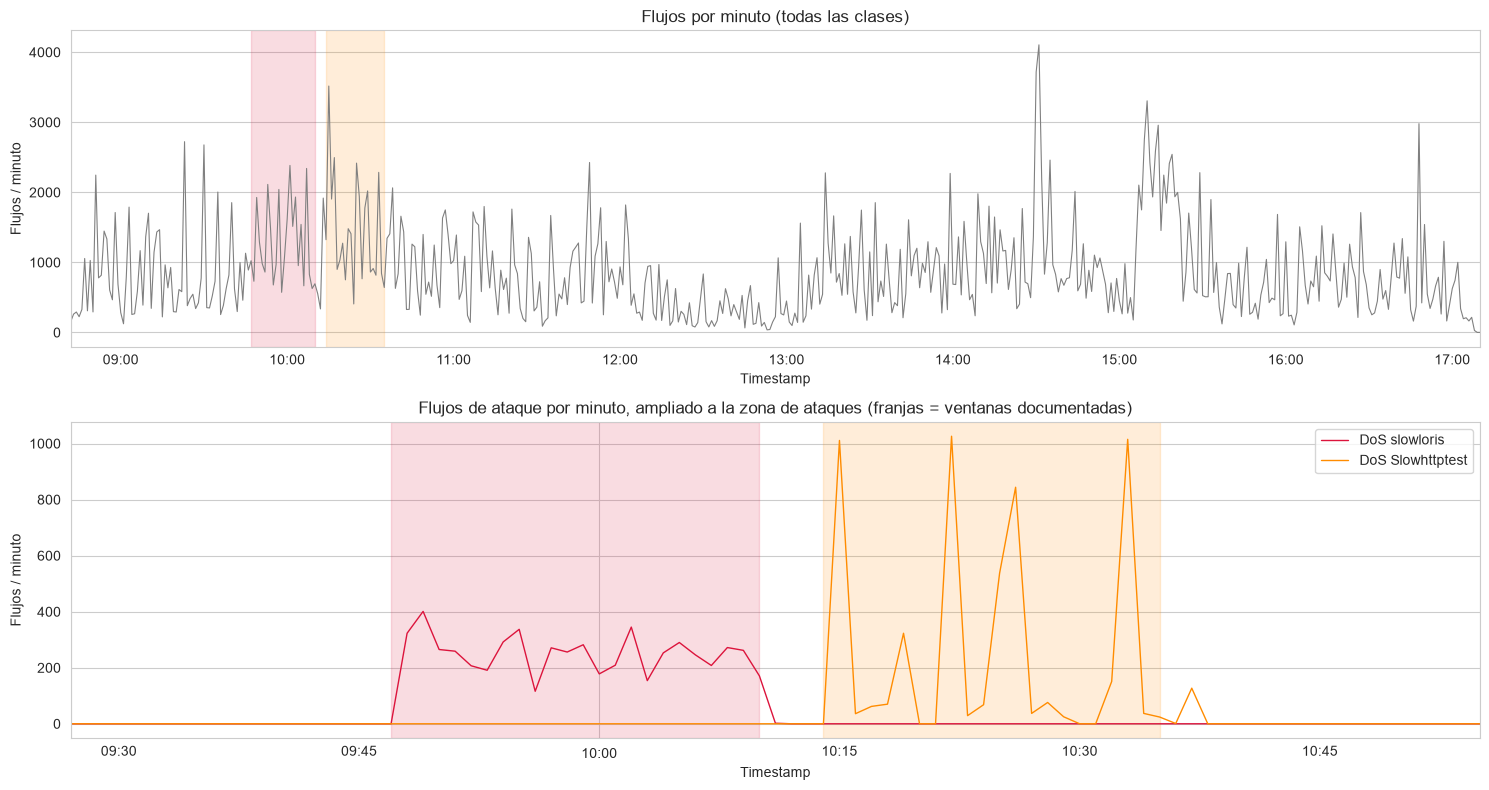

Rango temporal por clase:
                                 min                 max   count
Label                                                           
BENIGN           2017-07-05 08:42:00 2017-07-05 17:10:00  432325
DoS Slowhttptest 2017-07-05 10:15:00 2017-07-05 10:37:00    5499
DoS slowloris    2017-07-05 09:48:00 2017-07-05 10:11:00    5790


In [18]:
por_minuto = (
    df.groupby([pd.Grouper(key="Timestamp", freq="1min"), "Label"])
    .size()
    .unstack(fill_value=0)
)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8))

por_minuto.sum(axis=1).plot(ax=ax1, color="gray", lw=0.8)
ax1.set_title("Flujos por minuto (todas las clases)")
ax1.set_ylabel("Flujos / minuto")

for etiqueta in ["DoS slowloris", "DoS Slowhttptest"]:
    if etiqueta in por_minuto.columns:
        por_minuto[etiqueta].plot(ax=ax2, color=COLORES[etiqueta], lw=1, label=etiqueta)
ax2.set_title("Flujos de ataque por minuto, ampliado a la zona de ataques (franjas = ventanas documentadas)")
inicio_ataques = min(pd.Timestamp(ini) for ini, _ in VENTANAS_ATAQUE_DOCUMENTADAS.values())
fin_ataques = max(pd.Timestamp(fin) for _, fin in VENTANAS_ATAQUE_DOCUMENTADAS.values())
ax2.set_xlim(inicio_ataques - pd.Timedelta(minutes=20), fin_ataques + pd.Timedelta(minutes=20))
ax2.set_ylabel("Flujos / minuto")
ax2.legend()

for etiqueta, (ini, fin) in VENTANAS_ATAQUE_DOCUMENTADAS.items():
    for ax in (ax1, ax2):
        ax.axvspan(pd.Timestamp(ini), pd.Timestamp(fin), color=COLORES[etiqueta], alpha=0.15)

plt.tight_layout()
plt.savefig(FIG_DIR / "distribucion_temporal.png", dpi=150)
plt.show()

print("Rango temporal por clase:")
print(df.groupby("Label")["Timestamp"].agg(["min", "max", "count"]).to_string())

**5. Estadísticas descriptivas de las características clave**

Las características se agrupan según las magnitudes que nombra el primer objetivo específico del protocolo: duración de la conexión, número de paquetes, volumen de datos, tasa de envío e intervalos entre paquetes. Además de la descripción global, se compara la **mediana por clase**, más informativa que la media en distribuciones tan sesgadas.

`Flow Duration` y los IAT están en **microsegundos** (1,000,000 µs = 1 s). El máximo de 1.2 × 10⁸ µs (120 s) es el timeout de flujo de CICFlowMeter, así que ningún flujo dura más.

In [19]:
GRUPOS_FEATURES = {
    "Duración": ["Flow Duration"],
    "Paquetes": ["Total Fwd Packets", "Total Backward Packets"],
    "Volumen": ["Total Length of Fwd Packets", "Total Length of Bwd Packets",
                "Fwd Packet Length Mean", "Bwd Packet Length Mean"],
    "Tasa": ["Flow Bytes/s", "Flow Packets/s"],
    "Intervalos (IAT)": ["Flow IAT Mean", "Flow IAT Std", "Flow IAT Max", "Flow IAT Min",
                         "Fwd IAT Mean", "Fwd IAT Std", "Fwd IAT Max", "Fwd IAT Min"],
}
key_features = [c for grupo in GRUPOS_FEATURES.values() for c in grupo if c in df.columns]
faltantes = [c for grupo in GRUPOS_FEATURES.values() for c in grupo if c not in df.columns]
if faltantes:
    print(f"AVISO: features clave ausentes del dataset: {faltantes}")

print("Descripción global:")
display(df[key_features].describe().T)

print("Mediana por clase:")
display(df.groupby("Label")[key_features].median().T)

Descripción global:


,count,mean,std,min,25%,50%,75%,max
Flow Duration,443614.0,1.261637e+07,3.182068e+07,1.000000,186.000000,31230.000000,1.148682e+06,1.200000e+08
Total Fwd Packets,443614.0,6.501407e+00,1.721873e+02,1.000000,2.000000,2.000000,4.000000e+00,1.121410e+05
Total Backward Packets,443614.0,6.442817e+00,2.416894e+02,0.000000,1.000000,2.000000,2.000000e+00,1.573880e+05
Total Length of Fwd Packets,443614.0,5.675890e+02,5.261007e+03,0.000000,31.000000,68.000000,1.760000e+02,8.203280e+05
Total Length of Bwd Packets,443614.0,6.224549e+03,6.067782e+05,0.000000,6.000000,137.000000,3.440000e+02,3.990000e+08
Fwd Packet Length Mean,443614.0,5.414426e+01,1.156491e+02,0.000000,8.901580,38.000000,5.150000e+01,4.640758e+03
Bwd Packet Length Mean,443614.0,1.628411e+02,2.745320e+02,0.000000,6.000000,80.000000,1.610000e+02,3.675056e+03
Flow Bytes/s,443614.0,2.243372e+06,3.383403e+07,0.000000,155.940780,5268.812803,3.396226e+05,2.070000e+09
Flow Packets/s,443614.0,5.872316e+04,2.268652e+05,0.016722,7.590873,90.792162,2.020202e+04,3.000000e+06
Flow IAT Mean,443614.0,1.029642e+06,4.001472e+06,0.500000,70.000000,14759.058710,1.814216e+05,1.200000e+08


Mediana por clase:


Label,BENIGN,DoS Slowhttptest,DoS slowloris
Flow Duration,31000.000000,6.311764e+07,9.708569e+07
Total Fwd Packets,2.000000,7.000000e+00,3.000000e+00
Total Backward Packets,2.000000,0.000000e+00,2.000000e+00
Total Length of Fwd Packets,68.000000,0.000000e+00,1.600000e+01
Total Length of Bwd Packets,143.000000,0.000000e+00,0.000000e+00
Fwd Packet Length Mean,38.000000,0.000000e+00,8.000000e+00
Bwd Packet Length Mean,82.000000,0.000000e+00,0.000000e+00
Flow Bytes/s,5569.359952,0.000000e+00,2.210706e+00
Flow Packets/s,105.196718,1.109131e-01,1.798502e-01
Flow IAT Mean,12197.411760,1.050000e+07,5.869174e+06


**6. Distribuciones por clase**

Histogramas en escala `log1p` con **densidad** (área total = 1 por clase). Con conteos absolutos, la relación de 38:1 haría invisible la forma de los ataques. Se incluyen los valores cero (`log1p(0) = 0`) para no ocultar parte de la distribución.

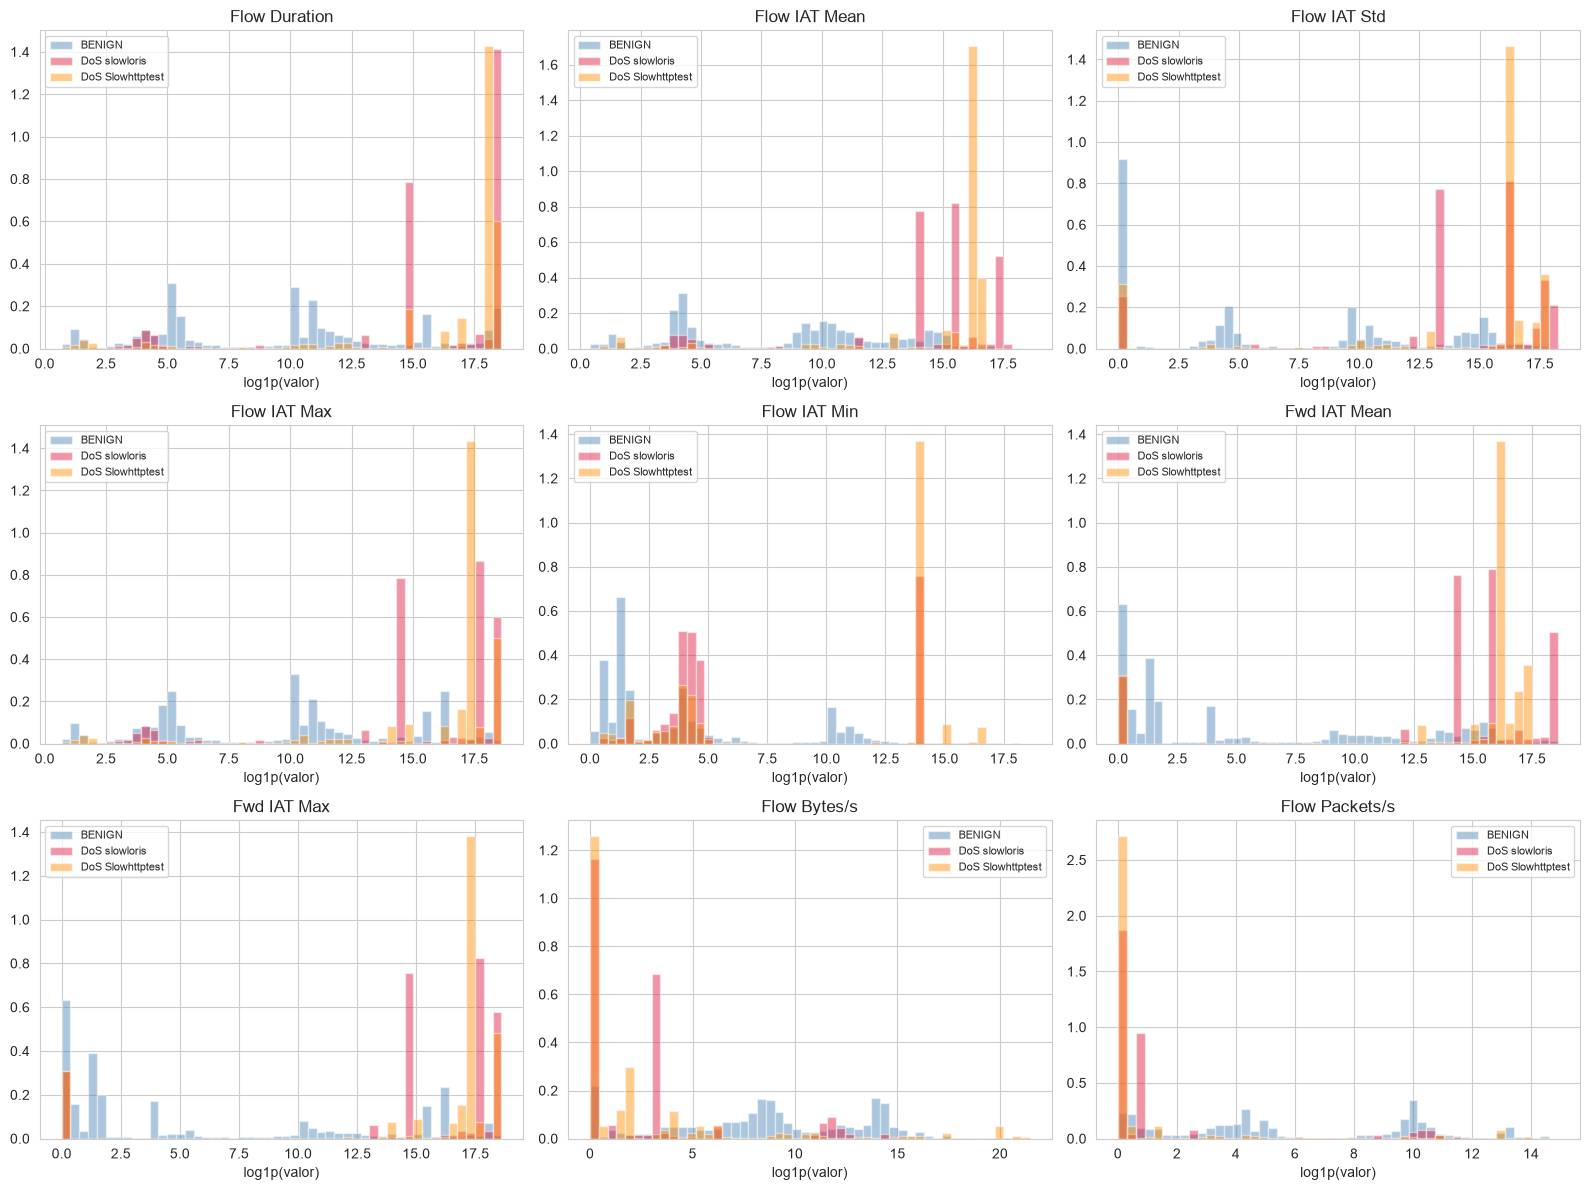

In [20]:
hist_features = [c for c in ["Flow Duration", "Flow IAT Mean", "Flow IAT Std", "Flow IAT Max",
                             "Flow IAT Min", "Fwd IAT Mean", "Fwd IAT Max",
                             "Flow Bytes/s", "Flow Packets/s"] if c in df.columns]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.flatten(), hist_features):
    valores = np.log1p(df[col].clip(lower=0))
    bins = np.histogram_bin_edges(valores, bins=50)
    for etiqueta, color in COLORES.items():
        ax.hist(valores[df["Label"] == etiqueta], bins=bins, density=True,
                alpha=0.45, color=color, label=etiqueta)
    ax.set_title(col)
    ax.set_xlabel("log1p(valor)")
    ax.legend(fontsize=8)
for ax in axes.flatten()[len(hist_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig(FIG_DIR / "histogramas_por_clase.png", dpi=150)
plt.show()

**7. Boxplots por clase (escala logarítmica)**

En escala lineal los boxplots quedan dominados por unos pocos valores extremos. En escala `log1p` se ve la separación entre clases en el rango donde está la mayoría de los flujos.

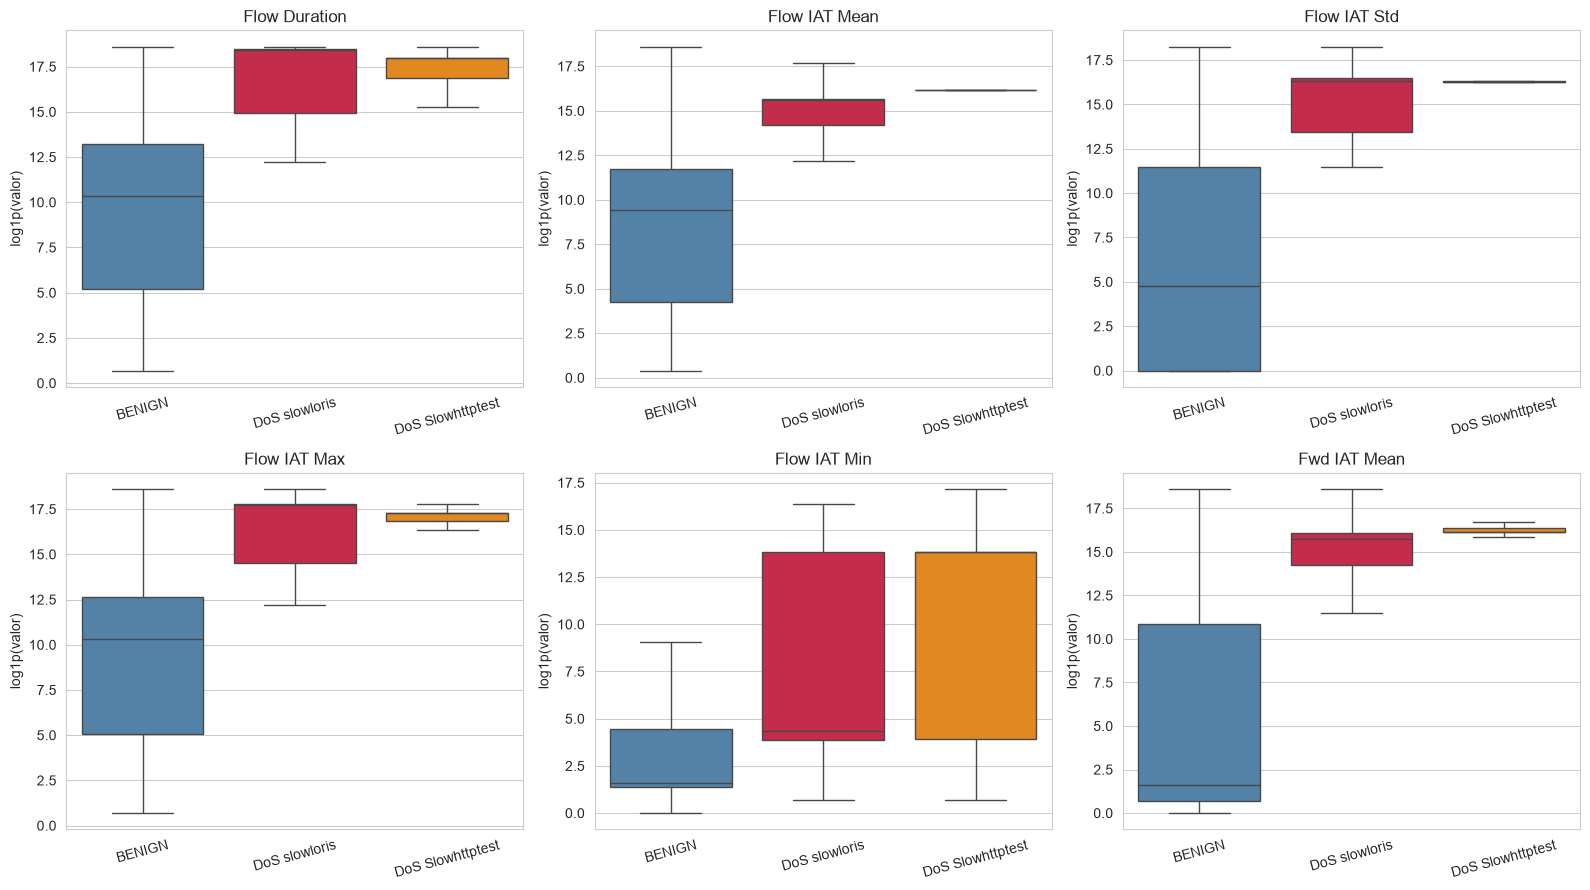

In [21]:
box_features = hist_features[:6]
df_log = df[box_features].clip(lower=0).apply(np.log1p).assign(Label=df["Label"])

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), box_features):
    sns.boxplot(data=df_log, x="Label", y=col, hue="Label", palette=COLORES,
                order=list(COLORES), legend=False, ax=ax, showfliers=False)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("log1p(valor)")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig(FIG_DIR / "boxplots_por_clase.png", dpi=150)
plt.show()

**8. Asociación de cada característica con la etiqueta**

Se usan tres medidas complementarias:

- **Pearson:** relación lineal. Es sensible a valores atípicos, lo que en estas variables (de 0 a 10⁸) puede distorsionarla.
- **Spearman:** relación monótona, basada en rangos. Es robusta a atípicos y da igual con o sin transformación logarítmica.
- **Información mutua (MI):** cualquier tipo de dependencia, incluso no monótona. Por eso es la referencia principal para modelos no lineales como el SVM con kernel RBF. Se estima con una muestra estratificada de 50,000 flujos para acotar el costo computacional y con las variables en escala logarítmica con signo, porque el estimador es más estable sin colas extremas.

Una correlación baja **no implica** que una característica sea inútil: puede aportar combinada con otras o de forma no lineal. La tabla es descriptiva y **no debe usarse para seleccionar características**, porque se calcula con todo el dataset, incluida la prueba.

In [22]:
pearson = df[features].corrwith(y)
spearman = df[features].corrwith(y, method="spearman")

X_mi, _, y_mi, _ = train_test_split(
    df[features], y, train_size=50_000, stratify=y, random_state=RANDOM_STATE
)
X_mi_log = np.sign(X_mi) * np.log1p(np.abs(X_mi))  # log con signo: admite el -1 de Init_Win_bytes_*
# Las columnas con pocos valores (banderas 0/1, etc.) se tratan como discretas: el estimador
# para variables continuas les daría una MI pequeña pero positiva aunque no aporten nada
discretas = (X_mi.nunique() <= 10).to_numpy()
X_mi_log.loc[:, discretas] = X_mi.loc[:, discretas]  # sin transformar
mi = pd.Series(
    mutual_info_classif(X_mi_log, y_mi, discrete_features=discretas, random_state=RANDOM_STATE),
    index=features,
)

asociacion = (
    pd.DataFrame({"pearson": pearson, "spearman": spearman, "info_mutua": mi})
    .sort_values("info_mutua", ascending=False)
)
asociacion.to_csv(FIG_DIR / "asociacion_con_etiqueta.csv")

print("Asociación de cada feature con label_binaria (ordenada por información mutua):")
display(asociacion.round(4))

Asociación de cada feature con label_binaria (ordenada por información mutua):


,pearson,spearman,info_mutua
Fwd IAT Max,0.3649,0.1864,0.0902
Flow IAT Max,0.3636,0.1914,0.0896
Flow Packets/s,-0.0326,-0.2043,0.0883
Fwd Packets/s,-0.0341,-0.1999,0.0874
Flow Duration,0.2262,0.1738,0.0872
Flow IAT Mean,0.3591,0.2067,0.0869
Fwd IAT Mean,0.2670,0.1936,0.0867
Fwd IAT Total,0.2285,0.1695,0.0825
Flow IAT Std,0.3513,0.1898,0.0815
Max Packet Length,-0.0428,-0.0583,0.0777


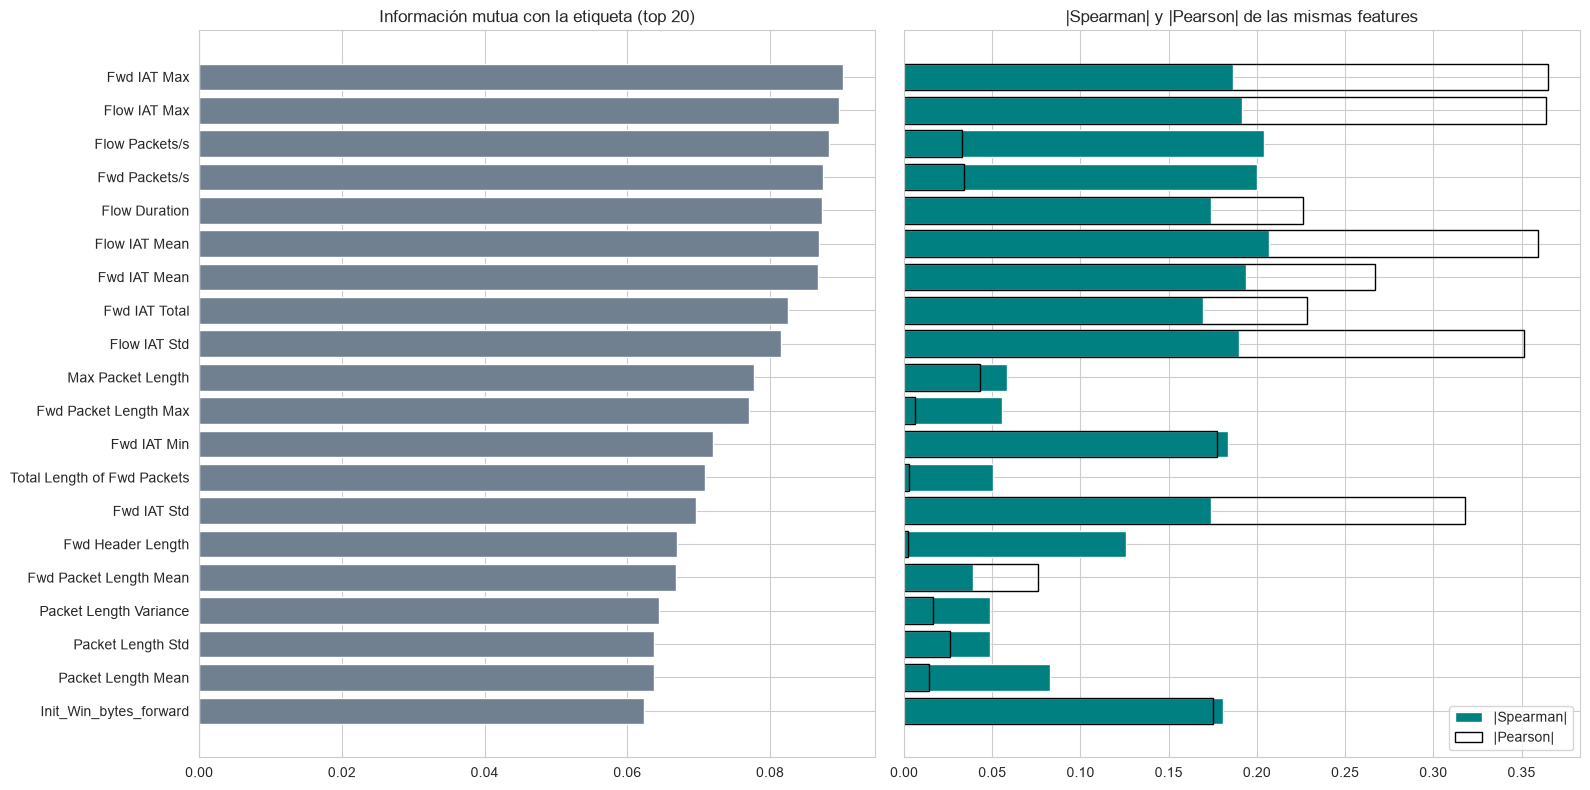

In [23]:
top = asociacion.head(20).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=True)
axes[0].barh(top.index, top["info_mutua"], color="slategray")
axes[0].set_title("Información mutua con la etiqueta (top 20)")
axes[1].barh(top.index, top["spearman"].abs(), color="teal", label="|Spearman|")
axes[1].barh(top.index, top["pearson"].abs(), color="none", edgecolor="black", label="|Pearson|")
axes[1].set_title("|Spearman| y |Pearson| de las mismas features")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "asociacion_top20.png", dpi=150)
plt.show()

**9. Multicolinealidad (diagnóstico)**

Se usa la correlación de **Spearman** entre características, que no depende de la escala ni de los atípicos. Se listan los pares con |ρ| > 0.9 y, aparte, los de |ρ| > 0.98, que son prácticamente la misma información.

Esta sección **solo diagnostica**. Las columnas a eliminar se deciden después, solo con la partición de entrenamiento. En el SVM conviene eliminar únicamente las casi idénticas.

El mapa usa agrupamiento jerárquico, así que las características muy correlacionadas quedan juntas en bloques.

In [24]:
corr_features = df[features].corr(method="spearman")

mask_superior = np.triu(np.ones(corr_features.shape, dtype=bool), k=1)
pares = (
    corr_features.where(mask_superior)
    .stack()
    .rename("rho")
    .reset_index()
    .rename(columns={"level_0": "Feature 1", "level_1": "Feature 2"})
)
pares["abs_rho"] = pares["rho"].abs()
pares_altos = pares[pares["abs_rho"] > 0.9].sort_values("abs_rho", ascending=False)

print(f"Pares con |Spearman| > 0.90: {len(pares_altos)}")
print(f"Pares con |Spearman| > 0.98: {int((pares_altos['abs_rho'] > 0.98).sum())}\n")
with pd.option_context("display.max_rows", None):
    display(pares_altos.drop(columns="abs_rho").round(4).reset_index(drop=True))

pares_altos.drop(columns="abs_rho").to_csv(FIG_DIR / "pares_alta_correlacion_spearman.csv", index=False)

Pares con |Spearman| > 0.90: 61
Pares con |Spearman| > 0.98: 31



,Feature 1,Feature 2,rho
0,Packet Length Std,Packet Length Variance,1.0000
1,Idle Mean,Idle Max,0.9993
2,Active Mean,Active Max,0.9986
3,Idle Mean,Idle Min,0.9984
4,Bwd IAT Mean,Bwd IAT Max,0.9982
5,RST Flag Count,ECE Flag Count,0.9979
6,Bwd IAT Total,Bwd IAT Max,0.9977
7,Idle Max,Idle Min,0.9970
8,Bwd IAT Total,Bwd IAT Mean,0.9969
9,Fwd IAT Total,Fwd IAT Max,0.9966


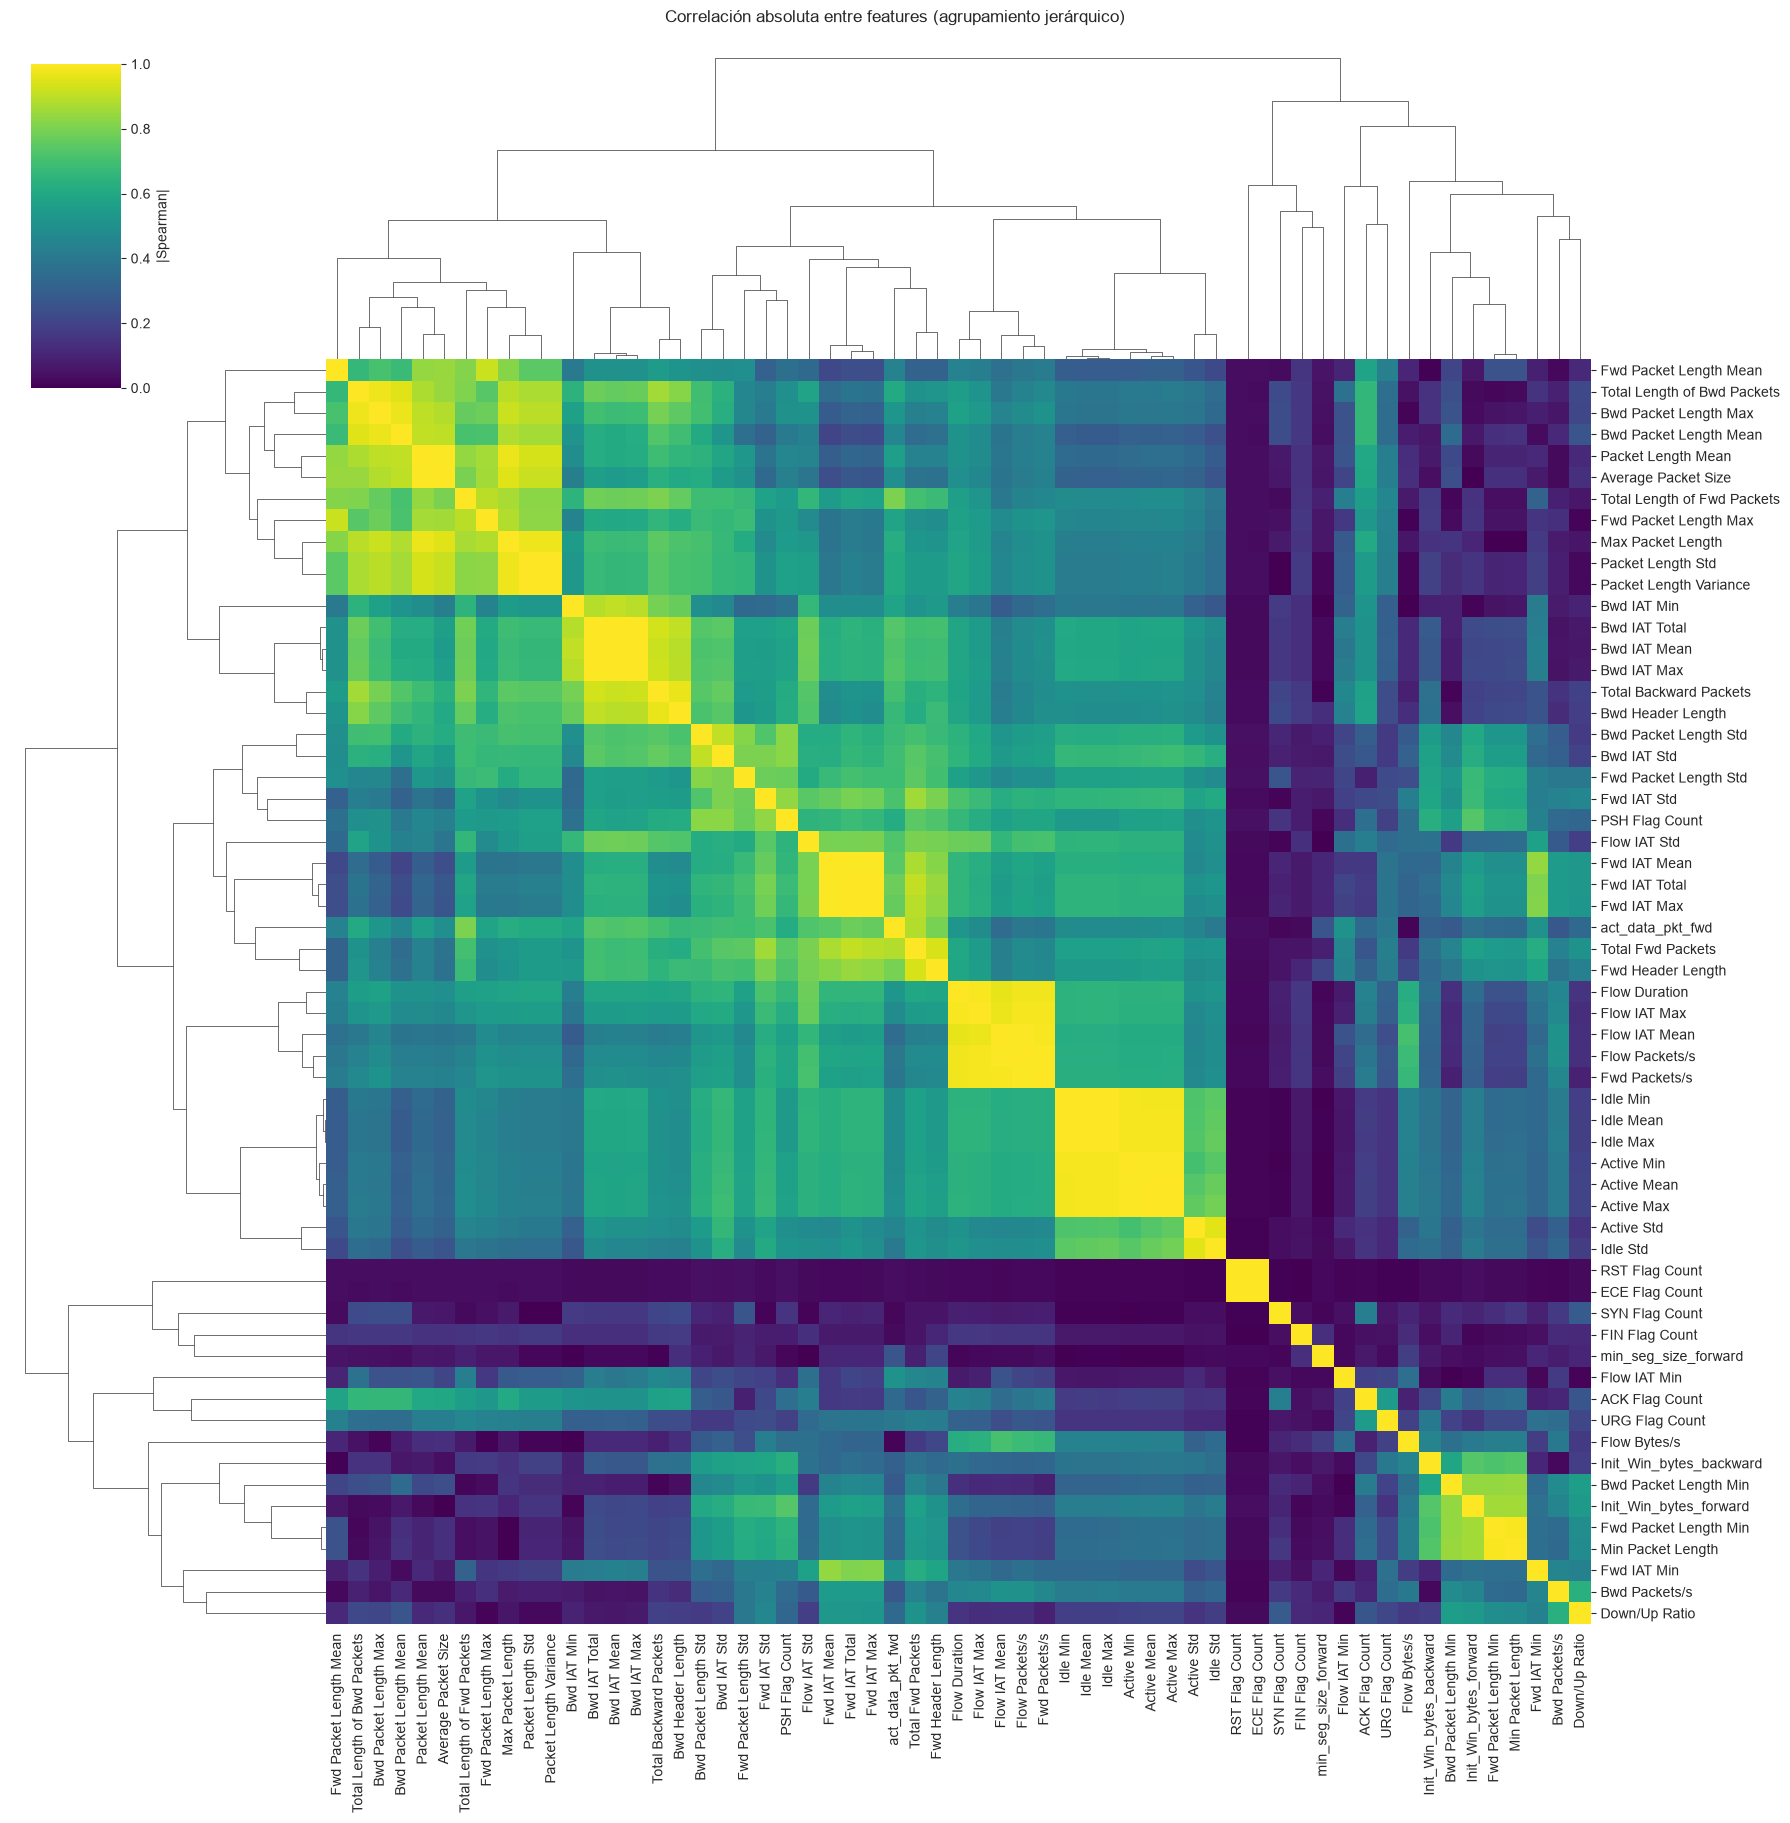

In [25]:
g = sns.clustermap(
    corr_features.abs(), cmap="viridis", vmin=0, vmax=1,
    figsize=(18, 18), xticklabels=True, yticklabels=True,
    cbar_kws={"label": "|Spearman|"},
)
g.fig.suptitle("Correlación absoluta entre features (agrupamiento jerárquico)", y=1.01)
g.savefig(FIG_DIR / "clustermap_correlacion.png", dpi=120)
plt.show()

**10. Posibles atajos: `Init_Win_bytes_*`**

`Destination Port` y `Protocol` ya se eliminaron por ser atajos del laboratorio. `Init_Win_bytes_forward` e `Init_Win_bytes_backward` (tamaño inicial de la ventana TCP) pueden comportarse igual: su valor depende sobre todo del sistema operativo y de la herramienta del atacante, no del comportamiento lento del ataque.

Si los ataques se concentran en pocos valores que casi no aparecen en el tráfico benigno, un modelo puede detectarlos solo con esa columna. Esta revisión justifica el experimento de ablación (con y sin estas columnas) previsto en cada módulo.

In [26]:
for col in ["Init_Win_bytes_forward", "Init_Win_bytes_backward"]:
    if col not in df.columns:
        print(f"{col}: no está en el dataset")
        continue

    print(f"=== {col} ===")
    top_valores = (
        df.groupby("Label")[col]
        .value_counts(normalize=True)
        .groupby(level=0)
        .head(3)
        .round(4)
    )
    print("Tres valores más frecuentes por clase (proporción dentro de la clase):")
    print(top_valores.to_string())

    # Qué tan exclusivos de los ataques son sus valores
    frecuencia_en_benigno = df.loc[y == 0, col].value_counts(normalize=True)
    frecuencia_de_valor_ataque = df.loc[y == 1, col].map(frecuencia_en_benigno).fillna(0)
    print(f"Ataques cuyo valor aparece en menos del 0.1% del tráfico benigno: "
          f"{(frecuencia_de_valor_ataque < 0.001).mean():.1%}\n")

=== Init_Win_bytes_forward ===
Tres valores más frecuentes por clase (proporción dentro de la clase):
Label             Init_Win_bytes_forward
BENIGN            -1                        0.4701
                   8192                     0.1212
                   29200                    0.1062
DoS Slowhttptest   29200                    0.7667
                   229                      0.1824
                   235                      0.0504
DoS slowloris      29200                    0.6682
                   229                      0.3307
                   387                      0.0003
Ataques cuyo valor aparece en menos del 0.1% del tráfico benigno: 2.5%

=== Init_Win_bytes_backward ===
Tres valores más frecuentes por clase (proporción dentro de la clase):
Label             Init_Win_bytes_backward
BENIGN            -1                         0.6015
                   0                         0.0293
                   60                        0.0189
DoS Slowhttptest  -1     

**11. Vectores de características repetidos**

El SVM solo ve las características, sin `Timestamp`, así que dos flujos con el mismo vector son para él el mismo ejemplo. Aquí se cuantifica el fenómeno en el dataset completo. Lo que importa para la evaluación, cuántos vectores de validación y prueba ya aparecen en entrenamiento, se mide después de la partición con `reportar_duplicados_de_features()` de `clean.py`.

Los vectores que aparecen **con ambas etiquetas** indican que, con estas características, esos flujos son indistinguibles: ningún modelo tabular puede clasificarlos todos bien.

In [27]:
hash_vector = pd.util.hash_pandas_object(df[features], index=False)

repetido = hash_vector.duplicated(keep=False)
print("Flujos cuyo vector de features aparece más de una vez:")
print(repetido.groupby(df["Label"]).agg(["sum", "mean"])
      .rename(columns={"sum": "filas", "mean": "proporción"}).round(4).to_string())

etiquetas_por_vector = y.groupby(hash_vector).transform("nunique")
conflictivos = etiquetas_por_vector > 1
print(f"\nFlujos cuyo vector aparece con ambas etiquetas: {int(conflictivos.sum()):,}")
print(df.loc[conflictivos, "Label"].value_counts().to_string())

Flujos cuyo vector de features aparece más de una vez:
                  filas  proporción
Label                              
BENIGN            62519      0.1446
DoS Slowhttptest    323      0.0587
DoS slowloris       507      0.0876

Flujos cuyo vector aparece con ambas etiquetas: 0
Series([], )


**12. Resumen**

La celda siguiente reúne las cifras principales del análisis.

In [28]:
print(f"Flujos: {len(df):,} | Features: {len(features)}")
print(f"Rango temporal: {df['Timestamp'].min()} -> {df['Timestamp'].max()}")
print(f"Ataques: {int(y.sum()):,} ({y.mean():.2%}) -> "
      f"{conteo.get('DoS slowloris', 0):,} Slowloris, {conteo.get('DoS Slowhttptest', 0):,} Slowhttptest")
print(f"Relación BENIGN : ataque ≈ {(y == 0).sum() / (y == 1).sum():.1f} : 1")
print(f"\nColumnas con valores negativos: {cols_con_negativos if cols_con_negativos else 'ninguna'}")
print(f"\nTop 10 features por información mutua:")
print(asociacion.head(10)[["info_mutua", "spearman"]].round(4).to_string())
print(f"\nPares de features con |Spearman| > 0.90: {len(pares_altos)} "
      f"(> 0.98: {int((pares_altos['abs_rho'] > 0.98).sum())})")
print(f"Flujos con vector repetido: {int(repetido.sum()):,} | "
      f"con vector en ambas clases: {int(conflictivos.sum()):,}")

Flujos: 443,614 | Features: 59
Rango temporal: 2017-07-05 08:42:00 -> 2017-07-05 17:10:00
Ataques: 11,289 (2.54%) -> 5,790 Slowloris, 5,499 Slowhttptest
Relación BENIGN : ataque ≈ 38.3 : 1

Columnas con valores negativos: ['Fwd Header Length', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'min_seg_size_forward']

Top 10 features por información mutua:
                   info_mutua  spearman
Fwd IAT Max            0.0902    0.1864
Flow IAT Max           0.0896    0.1914
Flow Packets/s         0.0883   -0.2043
Fwd Packets/s          0.0874   -0.1999
Flow Duration          0.0872    0.1738
Flow IAT Mean          0.0869    0.2067
Fwd IAT Mean           0.0867    0.1936
Fwd IAT Total          0.0825    0.1695
Flow IAT Std           0.0815    0.1898
Max Packet Length      0.0777   -0.0583

Pares de features con |Spearman| > 0.90: 61 (> 0.98: 31)
Flujos con vector repetido: 63,349 | con vector en ambas clases: 0


**Implicaciones para el modelado**

Estas conclusiones dependen de la forma de los datos, no de cifras exactas. Hay que contrastarlas con las salidas anteriores antes de citarlas en el informe.

- **Escala.** Duraciones, IAT y tasas abarcan varios órdenes de magnitud. El SVM debe aplicar log con signo y luego estandarización (en `03_b_Train_Model.ipynb` van dentro del `Pipeline`).
- **Desbalance.** Con una relación cercana a 38:1, la exactitud no es informativa. Conviene usar ponderación de clases o remuestreo solo sobre entrenamiento y evaluar con recall, precisión, F1, ROC-AUC y AP.
- **Señal temporal.** Si las características de duración e IAT encabezan la tabla de información mutua y las de volumen quedan abajo, se confirma la premisa del protocolo: el ataque se distingue por sus tiempos y no por la cantidad de tráfico.
- **Multicolinealidad.** Se decide solo con entrenamiento. Para el SVM basta eliminar los pares casi idénticos (> 0.98).
- **Atajos.** Si la sección 10 muestra valores de `Init_Win_bytes_*` casi exclusivos de los ataques, hay que reportar los resultados con y sin esas columnas.
- **Vectores conflictivos.** Su número fija un límite a lo que puede lograr un modelo tabular. Si es relevante, indica que parte de la información útil está en el contexto temporal de cada flujo, que un clasificador por flujo no ve.